# IND320- Project Work Part 4
**Student:** Sania Minaipour

### Links
- GitHub repository: https://github.com/Saniami/IND320-project
- Streamlit app: https://ind320-project-697hjpoelth3xk2xbtm6tk.streamlit.app/


## AI Usage

In this last part i used Claude to help me write the code, and it helped me with the new pages in the app.
In the notebook it helped me with the function for the API from Norges Bank, the timezone checks, and the
forecast function with River.

It helped me to understand and explain the difference between SARIMAX and SNARIMAX, and how to test the
forecast with several different start points in the past. It was also really useful when things went wrong,
for example when the lag model gave very bad forecasts because it learned the level of the fill too slowl,
and when i got a DNS error because MongoDB could not be reached.


Like earlier i ran all the code myself and looked at the plots and tables to see if they made sense. I chose
to get the data from the Norges Bank API as CSV instead of JSON, and I changed the background map to
OpenStreetMap when CARTO needed an API key. I used a first draft of the sketch from Claude as a starting point, and then made my own version in
PowerPoint and Google Drive, and I chose the default forecast setting based on my own test results. When I got an error, I read it
and tried to understand what was wrong before I fixed it.

I also used Claude for the text. It helped me with spelling and grammar, and it wrote first drafts of some
of the text in the notebook and the log, which I then changed to fit what i actually did.

### Setup

In [30]:
import io, json, time, tomllib
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import Image, display
from pymongo import MongoClient
from river import compose, linear_model, optim, preprocessing, time_series

DATA_DIR = Path("../data")

# Passwords are in a local file that is NOT on GitHub
with open("../.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)

#MongoDB from part 2 (the cross-border flows from ENTSO-E are stored here)
mongo = MongoClient(secrets["mongo"]["uri"])
db = mongo["ind320"]
print(db.list_collection_names())

['ping', 'crossborder_flows']


## Sketch of the app structure

Before changing the Streamlit code, I first listed all the elements the app should have in part 4 (left side
of the sketch). Then I drew where each element should be in the app, and marked it with its number, and added how i imagined the sidebar could look.

The pages are grouped by the type of task: **Explore**, **Anomalies** and **Forecast**, and each group has its
own colour, so it is easy to see which group is active.
Blue for Home, green for Explore, orange for Anomalies and purple
for Forecast. The colour is shown in the header of each page and in a box in the sidebar, so it is easy to
see which group is active. The theme is set in `.streamlit/config.toml`, and all Plotly plots use the same colours through a common template in `utils.py`, so the plots match the rest of the app.

The front page (**Home**) has the map, where the user
chooses the area by clicking, the week and the weather property. These choices are saved in
`st.session_state`, so they follow the user to the other pages. Selections that only matter for one page,
like the lag and window length in the correlation, stay on that page. The old LineChartColumn page is joined
with the plot page into one "Data overview" page. Elements 16-18 are used on all pages.

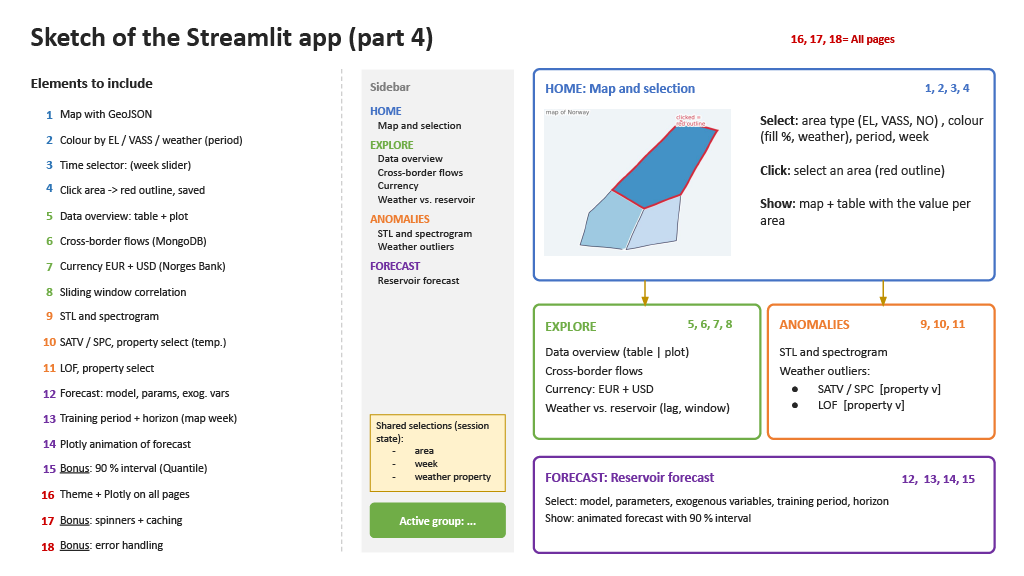

In [31]:
display(Image(filename="../figures/app_sketch.png"))

## Converting the shapefiles from part 3 to GeoJSON

The map in the Streamlit app needs the area outlines as GeoJSON, which is the format web maps can read. I use
the same shapefiles as in part 3: the price areas (EL) from `Budområder`, and the NVE regions, which I join
into the three water areas (VASS) in the same way as in part 3. The whole country (NO) is all price areas
joined together. The outlines are simplified to 1 km, so the file is small and the map loads fast, and the
coordinates are changed to longitude/latitude (EPSG:4326), which web maps use.

In [32]:
# Convert the shapefiles from part 3 to one GeoJSON file for the map in the app
import geopandas as gpd

bud = gpd.read_file(DATA_DIR / "Budområder" / "Budområder.shp", encoding="utf-8")    # price areas
reg = gpd.read_file(DATA_DIR / "NVE region" / "NVE_Region.shp", encoding="utf-8")     # NVE regions

def join(g):
    """Join several areas into one (union_all is the new name in geopandas 1.0)."""
    return g.union_all() if hasattr(g, "union_all") else g.unary_union

VASS_MAP = {1: ["RS", "RØ"], 2: ["RV"], 3: ["RM", "RN"]}              # same as in part 3

rows = [{"Area_Type": "EL", "Area_Number": int(r["budomr"][-1]), "name": f"NO {int(r['budomr'][-1])}",
         "geometry": r.geometry} for _, r in bud.iterrows()]
rows += [{"Area_Type": "VASS", "Area_Number": n, "name": f"VASS {n}",
          "geometry": join(reg[reg["REGION"].isin(codes)])} for n, codes in VASS_MAP.items()]
rows.append({"Area_Type": "NO", "Area_Number": 0, "name": "Norway", "geometry": join(bud)})

areas = gpd.GeoDataFrame(rows, crs=bud.crs)
areas["geometry"] = areas.geometry.simplify(1000)      # 1 km simplification (the data is in metres)
areas = areas.to_crs(4326)                              # longitude/latitude for web maps
areas.to_file(DATA_DIR / "areas.geojson", driver="GeoJSON")

print(f"Saved {len(areas)} areas, {(DATA_DIR / 'areas.geojson').stat().st_size / 1e6:.2f} MB")

Saved 9 areas, 0.11 MB


- `Saved 9 areas, 0.11 MB` means that the file has 9 areas (EL 1-5, VASS 1-3 and NO), and that it is only
  0.11 MB, so the map in the app loads fast.

## Download Euro and USD currency exchange rates 

In [33]:
NB_URL = "https://data.norges-bank.no/api/data/EXR/B.{cur}.NOK.SP" # {cur} is filled in by the function, so any currency can be chosen


def download_exchange_rates(currencies=("EUR", "USD"), start="2015-01-01", end=None):
    """Daily exchange rates (NOK per unit) from Norges Bank.
    currencies: currency codes.  start, end: 'YYYY-MM-DD' (end = today if None).
    Returns a DataFrame with the date as index and one column per currency."""
    end = end or pd.Timestamp.today().strftime("%Y-%m-%d")
    url = NB_URL.format(cur="+".join(currencies))            # several currencies are joined with +
    params = {"format": "csv", "startPeriod": start, "endPeriod": end, "locale": "en"}
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()

    # sep=None lets pandas find the separator itself
    df = pd.read_csv(io.StringIO(r.text), sep=None, engine="python")
    df = df[["BASE_CUR", "TIME_PERIOD", "OBS_VALUE"]]        # currency, date and value
    df["TIME_PERIOD"] = pd.to_datetime(df["TIME_PERIOD"])
    df["OBS_VALUE"] = pd.to_numeric(df["OBS_VALUE"], errors="coerce")
    rates = df.pivot(index="TIME_PERIOD", columns="BASE_CUR", values="OBS_VALUE")
    rates.index.name = "date"
    rates.columns.name = None
    return rates

(2994, 2)


,EUR,USD
date,,
2015-01-02,9.0420,7.5081
2015-01-05,9.1075,7.6437
2015-01-06,9.1795,7.7048


,EUR,USD
date,,
2026-11-19,10.6475,9.6866
2026-11-20,10.7180,9.7525
2026-11-23,10.7285,9.8076


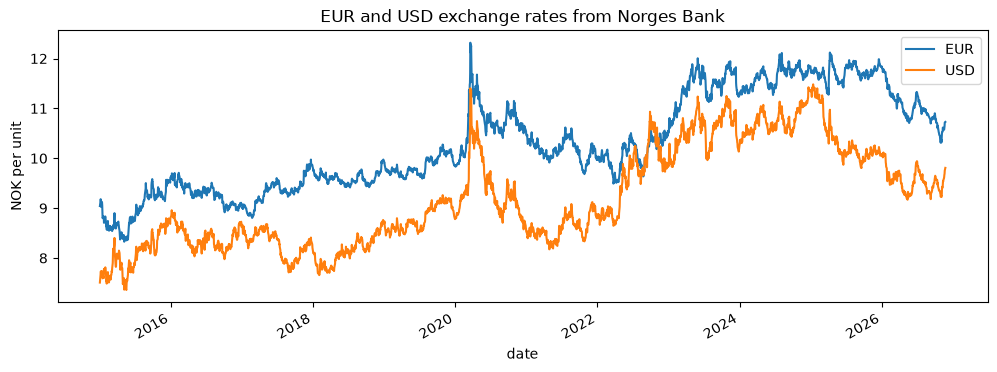

In [34]:
# Test: download EUR and USD from 2015 until today
rates = download_exchange_rates(start="2015-01-01")
print(rates.shape)
display(rates.head(3), rates.tail(3))

fig, ax = plt.subplots(figsize=(12, 4))
rates.plot(ax=ax)
ax.set_ylabel("NOK per unit"); ax.set_title("EUR and USD exchange rates from Norges Bank")
plt.show()

### Comments on the results 

- The function returns one row for the date, one column for EUR and one column for USD.

- In 2015, 1 euro cost about 9 NOK and 1 dollar about 7.5 NOK, and now it is over 10.5 and 9.5 NOK, so the krone has
  become weaker against both currencies over the years.

- The plot shows some big spikes, especially in March 2020 when corona started and the krone fell really
  fast. Both currencies were most expensive in 2023-2025. Since 2025 the krone has become a bit stronger
  again, mostly against USD, so the gap between EUR and USD is actually bigger now than it was a few years
  ago.



## Timezone differences between Magasinstatistikk, ENTSO-E, OpenMeteo and NB

I found out that the four sources store time in different ways. I looked at the documentation, at my own
code from part 2 and 3, and at the data itself (the checks are below).

| Source | Resolution | Time stamp in my data | Time zone |
|---|---|---|---|
| Magasinstatistikk (NVE) | weekly | `dato_Id` is a date (the Sunday of the ISO week), no clock time | Norwegian calendar |
| ENTSO-E | 15 min / hourly | entsoe-py returns Europe/Brussels time. In part 2 I converted it to UTC and saved it **without** time zone | UTC |
| Open-meteo | hourly / daily | in part 3 I asked for `timezone=UTC`, so the times are UTC **without** time zone | UTC (only if we ask for it) |
| Norges Bank | business days | only a date, no clock time. No values on weekends and public holidays | Norwegian calendar |

Norway and Brussels use the same time (CET in winter, CEST in summer), so ENTSO-E's own time is the same as
Norwegian time. The problem is that I saved it as UTC, and so is the weather data, while NVE and Norges Bank
use Norwegian dates. UTC is 1 hour behind Norwegian time in winter and 2 hours in summer. That means:

- A day or a week made from UTC hours starts 1-2 hours later than the Norwegian day or week.
- When the clock changes, the Norwegian day has 23 or 25 hours.
- Norges Bank has gaps on weekends and holidays, so the rates must be filled before they can be joined
  with the other weekly or daily data.

In [35]:
# Check 1: Magasinstatistikk. Which weekdays are the dates? (0 = Monday, 6 = Sunday)
BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"
r = requests.get(f"{BASE}/HentOffentligData", headers={"Accept": "application/json"}, timeout=120)
r.raise_for_status()
res = (pd.DataFrame(r.json())
         .rename(columns={"dato_Id": "Date", "omrType": "Area_Type", "omrnr": "Area_Number",
                          "fyllingsgrad": "Fill_Percentage"}))
res["Date"] = pd.to_datetime(res["Date"])
res = res.sort_values(["Area_Type", "Area_Number", "Date"])
print("Magasinstatistikk weekdays:", res["Date"].dt.dayofweek.value_counts().to_dict())

# Check 2: Norges Bank. Only Monday-Friday, and some weekdays are missing (public holidays)
print("Norges Bank weekdays:", rates.index.dayofweek.value_counts().sort_index().to_dict())
all_weekdays = pd.bdate_range(rates.index.min(), rates.index.max())
print("Weekdays without a rate (holidays):", len(all_weekdays.difference(rates.index)))

Magasinstatistikk weekdays: {6: 14967}
Norges Bank weekdays: {0: 587, 1: 611, 2: 610, 3: 588, 4: 598}
Weekdays without a rate (holidays): 108


- `Magasinstatistikk weekdays: {6: 14967}` means that all 14 967 dates are weekday 6, which is Sunday(Monday=0). So each value belongs to one week, and the date is the last day of that week.

- `Norges Bank weekdays: {0: 586, 1: 611, 2: 610, 3: 588, 4: 598}` means that Norges Bank only has values for Monday (0) to Friday (4), so there are no rates on weekends. Mondays and Thursdays have the fewest values, because Easter, Ascension Day and Whit Monday fall on these days.

- `Weekdays without a rate (holidays): 108` means that 108 weekdays have no rate. This is about 9 public holidays per year, which fits with the number of Norwegian public holidays.

In [36]:
# Check 3: ENTSO-E in MongoDB. The time is saved without time zone (UTC from part 2)
doc = db["crossborder_flows"].find_one({}, {"_id": 0})
print(doc)

# Check 4: how much does it matter? The weather for EL 3 in 2024 (hourly, UTC) from part 3.
# Make weekly and daily values once in UTC and once in Norwegian time, and compare.
w = pd.read_csv(DATA_DIR / "weather_cache" / "EL3_2024-01-01_2024-12-31.csv", index_col="time", parse_dates=True)
w_oslo = w.tz_localize("UTC").tz_convert("Europe/Oslo")       # same hours, Norwegian clock

def no_tz(s):                                                  # remove the time zone so the indexes can be compared
    s.index = s.index.tz_localize(None).normalize()
    return s

temp_w = (w["temperature_2m"].resample("W-SUN").mean() - no_tz(w_oslo["temperature_2m"].resample("W-SUN").mean())).dropna()
prec_w = (w["precipitation"].resample("W-SUN").sum() - no_tz(w_oslo["precipitation"].resample("W-SUN").sum())).dropna()
prec_d = (w["precipitation"].resample("D").sum() - no_tz(w_oslo["precipitation"].resample("D").sum())).dropna()

print(f"Weekly temperature:   mean difference {temp_w.abs().mean():.3f} °C, max {temp_w.abs().max():.3f} °C")
print(f"Weekly precipitation: mean difference {prec_w.abs().mean():.2f} mm, max {prec_w.abs().max():.2f} mm "
      f"(the mean week has {w['precipitation'].resample('W-SUN').sum().mean():.1f} mm)")
print(f"Daily precipitation:  mean difference {prec_d.abs().mean():.2f} mm, max {prec_d.abs().max():.2f} mm")
print("Hours on 31 March and 27 October in Norwegian time:",
      len(w_oslo.loc["2024-03-31"]), len(w_oslo.loc["2024-10-27"]))

{'from_area': 'NL', 'to_area': 'NO_2', 'ts': datetime.datetime(2024, 10, 14, 22, 0), 'mw': 0.0}
Weekly temperature:   mean difference 0.030 °C, max 0.126 °C
Weekly precipitation: mean difference 0.34 mm, max 1.55 mm (the mean week has 33.9 mm)
Daily precipitation:  mean difference 0.35 mm, max 2.51 mm
Hours on 31 March and 27 October in Norwegian time: 23 25


- `{'from_area': 'NL', 'to_area': 'NO_2', 'ts': datetime.datetime(2024, 10, 16, 16, 0), 'mw': 0.0}` means that the time in MongoDB is saved without a time zone. I know from part 2 that it is UTC, so 16:00 was really 18:00 in Norwegian time, since it was summer time.
- `Weekly temperature: mean difference 0.030 °C, max 0.126 °C` means that the weekly mean temperature almost does not change when I use Norwegian time instead of UTC.
- `Weekly precipitation: mean difference 0.34 mm, max 1.55 mm (the mean week has 33.9 mm)` means that the weekly precipitation changes with only about 1 %, so the time zone matters little for weekly values.
- `Daily precipitation: mean difference 0.35 mm, max 2.51 mm` means that for single days the difference is bigger, because rain late in the evening can end up on the next day in UTC.
- `Hours on 31 March and 27 October in Norwegian time: 23 25` means that in Norwegian time, 31 March has only 23 hours and 27 October has 25 hours, because of the change to and from summer time.

### Findings and solution

- **Magasinstatistikk** dates are all Sundays, so one value belongs to one ISO week (Monday-Sunday).
- **Norges Bank** only has Monday-Friday, and some weekdays are missing because of public holidays.
- **ENTSO-E** in MongoDB and the **weather** from part 3 are in UTC without time zone, so it is easy to think
  they are Norwegian time.
- The effect of the shift is small for weekly values: the weekly mean temperature changes with at most about
  0.13 °C, and weekly precipitation with about 0.3 mm on average (about 1 % of a normal week). For daily
  values it matters more, because a rain shower in the evening can end up on the wrong day (up to 2.5 mm).
- When the clock changes, the Norwegian day has 23 hours (31 March) or 25 hours (27 October).

**Solution:** All data is changed to Norwegian time (`Europe/Oslo`) before it is joined, and then made into
weekly values with `resample("W-SUN")`. This gives weeks from Monday to Sunday, labelled with the Sunday,
exactly like Magasinstatistikk.
- Hourly data in UTC (ENTSO-E, old weather): `tz_localize("UTC").tz_convert("Europe/Oslo")`.
- New weather data: I ask open-meteo for `timezone=Europe/Oslo`, so the days are already Norwegian days.
- Norges Bank: fill weekends and holidays with the last known rate (`ffill`), then the weekly mean.

In [37]:
def to_weekly(s, how="mean", source_tz=None):
    """Make a weekly series (Monday-Sunday, labelled with the Sunday, like Magasinstatistikk).
    source_tz: the time zone of the data if it has none, e.g. "UTC". It is changed to Norwegian time first."""
    s = s.copy()
    if source_tz is not None:
        s.index = s.index.tz_localize(source_tz).tz_convert("Europe/Oslo").tz_localize(None)
    weekly = s.resample("W-SUN").agg(how)
    weekly.index = weekly.index.normalize()
    return weekly

def rates_weekly(rates):
    """Norges Bank: fill weekends and holidays with the last rate, then the weekly mean."""
    daily = rates.asfreq("D").ffill()
    return to_weekly(daily, "mean")

rates_w = rates_weekly(rates)
rates_w.tail()

,EUR,USD
date,,
2026-11-01,10.351143,9.275571
2026-11-08,10.443929,9.327429
2026-11-15,10.576286,9.519757
2026-11-22,10.650786,9.690986
2026-11-29,10.728500,9.807600


## Forecasting the reservoir filling with River

### Time resolution
The fill percentage from Magasinstatistikk, only has one value per week. A model on daily or hourly data would therefore not get more information about the target, only more rows to go through. So I use **weekly** data for the model.

For the weather I ask open-meteo for **daily** values (`daily=...`) instead of hourly values as in part 3. This means it's 24 times less data to download and handle, and open-meteo can make the daily values in Norwegian time. The daily values are then made into weekly values (mean temperature, sum of precipitation and snowfall). To keep the download time and the number of API calls down, I use at most 10 grid cells per area (picked with the weights from part 3).

### Data sources the function can use
- `"weather"`: temperature, precipitation and snowfall for the area (open-meteo, ERA5).
- `"currency"`: EUR and USD from Norges Bank.
- `"flows"`: net export of power from the chosen price area (or all of Norway) from ENTSO-E in MongoDB. In part 2 I only downloaded the connections from NO 1 and NO 2, so for the other areas all of Norway is used. The data only covers the last two years, so it is only used when the history is short enough (sources that cover less than 80 % of the history are dropped automatically).

In [38]:
locations = pd.read_csv(DATA_DIR / "locations.csv")             # the 1000 random points per area from part 3
DAILY = ["temperature_2m_mean", "precipitation_sum", "snowfall_sum"]
CACHE = DATA_DIR / "weather_cache"; CACHE.mkdir(exist_ok=True)

def download_weather_daily(area_type, area_number, start, end, max_cells=10):
    """Daily weather for one area, in Norwegian time. Same idea as in part 3: snap the points to
    the ERA5 grid (0.25°) and use a weighted mean of the grid cells."""
    cache_file = CACHE / f"daily_{area_type}{area_number}_{start}_{end}.csv"
    if cache_file.exists():                                    # already downloaded
        return pd.read_csv(cache_file, index_col="time", parse_dates=True)

    t0 = time.perf_counter()
    loc = locations[(locations.Area_Type == area_type) & (locations.Area_Number == area_number)]
    cells = (loc.assign(lat=(loc.lat * 4).round() / 4, lon=(loc.lon * 4).round() / 4)
                .groupby(["lat", "lon"]).size().rename("weight").reset_index())
    if len(cells) > max_cells:                                 # fewer cells = faster and fewer API calls
        cells = cells.sample(max_cells, weights="weight", random_state=0)

    params = {"latitude": ",".join(map(str, cells.lat)), "longitude": ",".join(map(str, cells.lon)),
              "start_date": start, "end_date": end, "daily": ",".join(DAILY),
              "models": "era5", "timezone": "Europe/Oslo"}    # days in Norwegian time
    for attempt in range(5):                                   # wait and retry if rate-limited
        r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=300)
        if r.status_code != 429:
            break
        print("Rate-limited, waiting 60 s ..."); time.sleep(60)
    r.raise_for_status()
    js = r.json(); js = js if isinstance(js, list) else [js]

    frames = []
    for wgt, j in zip(cells.weight, js):
        f = pd.DataFrame(j["daily"]); f["weight"] = wgt
        frames.append(f)
    d = pd.concat(frames); d["time"] = pd.to_datetime(d["time"])
    out = (d[DAILY].mul(d["weight"], axis=0).groupby(d["time"]).sum()
              .div(d.groupby("time")["weight"].sum(), axis=0))
    out.to_csv(cache_file)
    print(f"{area_type} {area_number}: {len(cells)} grid cells, {len(out)} days, {time.perf_counter() - t0:.1f} s")
    return out

def weather_weekly(area_type, area_number, start, end):
    """Weekly weather: mean temperature, and the sum of precipitation and snowfall."""
    d = download_weather_daily(area_type, area_number, start, end)
    return pd.concat([to_weekly(d["temperature_2m_mean"], "mean"),
                      to_weekly(d["precipitation_sum"], "sum"),
                      to_weekly(d["snowfall_sum"], "sum")], axis=1)

def flows_weekly(area_type, area_number):
    """Weekly mean net export (MW) from ENTSO-E in MongoDB. Positive = Norway exports.
    For a price area (EL) only the connections from that area are used, otherwise all of Norway."""
    df = pd.DataFrame(list(db["crossborder_flows"].find({}, {"_id": 0})))
    prefix = f"NO_{area_number}" if area_type == "EL" else "NO"
    if not (df.from_area.str.startswith(prefix) | df.to_area.str.startswith(prefix)).any():
        print(f"No foreign connections stored for {prefix} in part 2, using all of Norway instead.")
        prefix = "NO"
    out_ = df[df.from_area.str.startswith(prefix) & ~df.to_area.str.startswith("NO")]
    in_ = df[df.to_area.str.startswith(prefix) & ~df.from_area.str.startswith("NO")]
    net = out_.groupby("ts")["mw"].sum().sub(in_.groupby("ts")["mw"].sum(), fill_value=0)
    net.index = pd.to_datetime(net.index)
    return to_weekly(net, "mean", source_tz="UTC").rename("net_export_mw").to_frame()   # stored as UTC in part 2

def fill_series(area_type="EL", area_number=3):
    """Weekly fill percentage (0-100) for one area."""
    d = res[(res.Area_Type == area_type) & (res.Area_Number == area_number)]
    s = d.set_index("Date")["Fill_Percentage"].asfreq("W-SUN", method="ffill")
    return s * 100 if s.max() <= 1.5 else s                    # NVE gives a share (0-1), I use percent

In [39]:
def build_exog(sources, area_type, area_number, start="2018-01-01", end=None):
    """Weekly exogenous variables from the chosen data sources, joined on the same weeks."""
    end = end or (pd.Timestamp.today() - pd.Timedelta(days=7)).strftime("%Y-%m-%d")   # ERA5 is a few days behind
    parts = []
    if "weather" in sources:
        parts.append(weather_weekly(area_type, area_number, start, end))
    if "currency" in sources:
        parts.append(rates_weekly(rates))
    if "flows" in sources:
        parts.append(flows_weekly(area_type, area_number))
    return pd.concat(parts, axis=1, sort=True) if parts else None

# Download the data for EL 3 once (cached to disk after the first time)
fill = fill_series("EL", 3)
exog_all = build_exog(["weather", "currency", "flows"], "EL", 3)
print(fill.index.min().date(), fill.index.max().date(), len(fill))
exog_all.describe().round(2)

No foreign connections stored for NO_3 in part 2, using all of Norway instead.
1995-01-08 2026-11-15 1663


,temperature_2m_mean,precipitation_sum,snowfall_sum,EUR,USD,net_export_mw
count,464.00,464.00,464.00,621.00,621.00,105.00
mean,5.20,29.34,3.61,10.31,9.21,848.88
std,5.99,23.57,5.49,0.96,1.01,1118.72
min,-10.93,0.00,0.00,8.38,7.44,-1811.78
25%,1.02,10.22,0.00,9.53,8.40,204.61
50%,4.82,25.33,0.75,10.12,8.91,898.36
75%,10.25,42.23,5.17,11.26,10.09,1660.42
max,19.68,131.94,32.83,12.05,11.42,3337.84


- `EL 3: 10 grid cells, 3242 days, 3.5 s` means that the daily weather from 2018 until now was downloaded for
  10 grid cells in only 3.5 seconds. With hourly data as in part 3 it would be 24 times more values.

- `No foreign connections stored for NO_3 ...` means that I only downloaded the flows for NO 1 and NO 2 in
  part 2, so for EL 3 the net export for all of Norway is used.
  
- `1995-01-08 2026-11-15 1663` means that the fill for EL 3 goes back to 1995 and has 1663 weeks.
- The table shows that the weather has 464 weeks (from 2018), the exchange rates 621 weeks (from 2015) and
  the flows only 105 weeks (two years). So the flows can only be used with a short history.

## The forecast function

River does not have SARIMAX, but it has **SNARIMAX** (Seasonal Non-linear AutoRegressive Integrated Moving Average with eXogenous inputs), which is the same idea and learns one week at a time. As an alternative I also made a **lag model**: a linear regression on the fill in the last weeks, which forecasts one weekat a time and uses each forecast as a new lag.

Both models also get the week of the year as a sine and a cosine, so that week 52 and week 1 are close to each other. When we forecast, we do not know the weather or the exchange rate for the coming weeks. For weather I use the mean of the same week in the training years, and for the exchange rates the last known value.

The function has these parameters:
- `area_type`, `area_number`: the region, as in Magasinstatistikk. The default is EL 3.
- `sources`: which data sources to use: `"weather"`, `"currency"` and/or `"flows"`. An empty list means that only the fill itself is used. The default is weather.
- `model`: `"snarimax"` or `"lags"`. The default is SNARIMAX.
- `p, d, q`: how many past weeks (p) and past errors (q) the model uses, and how many times the series is differenced (d). The default is p=2, d=1, q=0.
- `sp, sd, sq, m`: the same, but for the season. `m=52` weeks is one year. The default is sd=1, so the model looks at the change from the same week last year.
- `n_lags`: how many past weeks the lag model uses. The default is 4.
- `history_weeks`: how many weeks of history the model learns from. The default is 260 weeks (5 years).
- `horizon`: how many weeks ahead to forecast. The default is 12 weeks, which is about 3 months.

In [40]:
def _season(ts):
    """Week of the year as sine and cosine."""
    w = ts.isocalendar()[1]
    return {"sin_week": np.sin(2 * np.pi * w / 52.18), "cos_week": np.cos(2 * np.pi * w / 52.18)}

def _future_exog(X, future_index):
    """Exogenous values for the forecast weeks: climatology for weather/flows, last value for currency."""
    out = pd.DataFrame(index=future_index, columns=X.columns, dtype=float)
    week = X.index.isocalendar().week
    for c in X.columns:
        if c in ("EUR", "USD"):
            out[c] = X[c].iloc[-1]
        else:
            clim = X[c].groupby(week).mean()
            out[c] = [clim.get(w, X[c].mean()) for w in future_index.isocalendar().week]
    return out

def forecast_fill(fill, exog=None, model="snarimax", history_weeks=260, horizon=12,
                  p=2, d=1, q=0, sp=0, sd=1, sq=0, m=52, n_lags=4, lr=0.01, end=None):
    """Forecast of a weekly fill series. Used by forecast_reservoir() below and by the backtest.
    end: last week of the training data (default: the last week we have).
    Returns (DataFrame with history and forecast, run time in seconds)."""
    t0 = time.perf_counter()
    y = fill.dropna()
    if end is not None:
        y = y[:end]
    y = y.iloc[-history_weeks:]                                # length of history
    future_index = pd.date_range(y.index[-1] + pd.Timedelta(weeks=1), periods=horizon, freq="W-SUN")

    X = X_future = None
    if exog is not None:
        X = exog.reindex(y.index)
        X = X.loc[:, X.isna().mean() < 0.2]                    # drop sources that do not cover the history
        X = X.ffill().bfill()
        if X.shape[1] == 0:
            X = None
        else:
            X_future = _future_exog(X, future_index)

    def feats(ts, row):
        f = _season(ts)
        if row is not None:
            f.update({k: float(v) for k, v in row.items()})
        return f

    # The regressor standardises the inputs and learns with stochastic gradient descent
    def regressor():
        return compose.Pipeline(preprocessing.StandardScaler(),
                                linear_model.LinearRegression(optimizer=optim.SGD(lr), intercept_lr=lr))

    if model == "snarimax":
        mdl = time_series.SNARIMAX(p=p, d=d, q=q, m=m, sp=sp, sd=sd, sq=sq, regressor=regressor())
        for ts, val in y.items():                              # learn one week at a time
            mdl.learn_one(val, x=feats(ts, X.loc[ts] if X is not None else None))
        xs = [feats(ts, X_future.loc[ts] if X is not None else None) for ts in future_index]
        pred = mdl.forecast(horizon=horizon, xs=xs)

    elif model == "lags":
        # The target (about 60 %) is also standardised, otherwise one pass of SGD is too slow to learn the level
        mdl = preprocessing.TargetStandardScaler(regressor=regressor())
        vals = list(y.values)
        def lag_feats(hist, ts, row):
            f = feats(ts, row)
            f.update({f"lag_{k}": hist[-k] for k in range(1, n_lags + 1)})
            return f
        for i in range(n_lags, len(y)):                        # learn one week at a time
            ts = y.index[i]
            mdl.learn_one(lag_feats(vals[:i], ts, X.loc[ts] if X is not None else None), y.iloc[i])
        hist, pred = vals.copy(), []
        for ts in future_index:                                # each forecast becomes a new lag
            yhat = mdl.predict_one(lag_feats(hist, ts, X_future.loc[ts] if X is not None else None))
            pred.append(yhat); hist.append(yhat)
    else:
        raise ValueError("model must be 'snarimax' or 'lags'")

    pred = np.clip(pred, 0, 100)                               # a fill percentage is between 0 and 100
    out = pd.concat([pd.DataFrame({"fill": y, "kind": "history"}),
                     pd.DataFrame({"fill": pred, "kind": "forecast"}, index=future_index)])
    return out, time.perf_counter() - t0


def forecast_reservoir(area_type="EL", area_number=3, sources=("weather",), model="snarimax",
                       history_weeks=260, horizon=12, **model_params):
    """Forecast of the coming weeks' reservoir filling for one region in Magasinstatistikk.
    Downloads/collects the data and calls forecast_fill()."""
    y = fill_series(area_type, area_number)
    exog = build_exog(list(sources), area_type, area_number)
    return forecast_fill(y, exog, model=model, history_weeks=history_weeks, horizon=horizon, **model_params)

Run time: 0.08 s


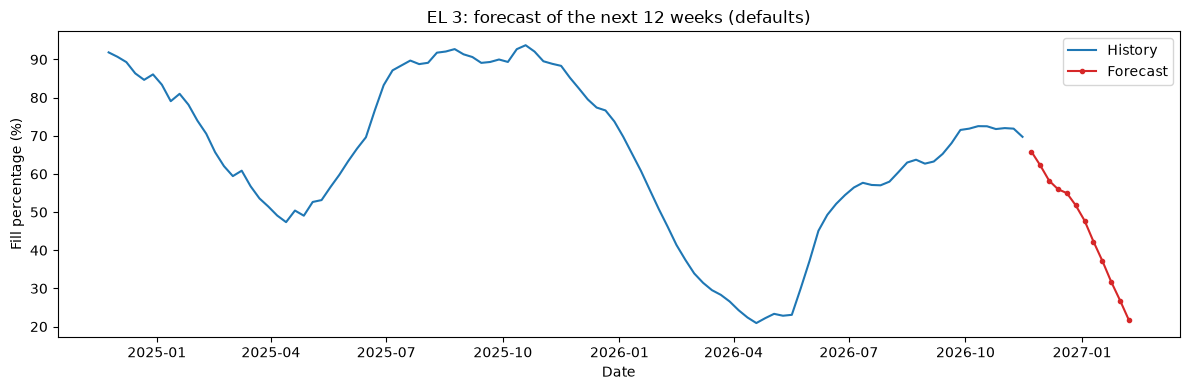

,2026-11-22,2026-11-29,2026-12-06,2026-12-13,2026-12-20,2026-12-27,2027-01-03,2027-01-10,2027-01-17,2027-01-24,2027-01-31,2027-02-07
fill,65.9,62.2,58.2,56.0,55.0,51.8,47.7,42.3,37.2,31.7,26.8,21.6
kind,forecast,forecast,forecast,forecast,forecast,forecast,forecast,forecast,forecast,forecast,forecast,forecast


In [41]:
def plot_forecast(result, actual=None, title=""):
    """The last two years of history, the forecast and (if given) what really happened."""
    hist = result[result.kind == "history"]["fill"].iloc[-104:]
    fc = result[result.kind == "forecast"]["fill"]
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(hist.index, hist, label="History")
    ax.plot(fc.index, fc, color="tab:red", marker="o", ms=3, label="Forecast")
    if actual is not None:
        a = actual.reindex(fc.index)
        ax.plot(a.index, a, color="black", ls="--", label="Actual")
    ax.set_xlabel("Date"); ax.set_ylabel("Fill percentage (%)"); ax.set_title(title); ax.legend()
    fig.tight_layout()
    return fig

# Test with the defaults
result, sec = forecast_reservoir()
print(f"Run time: {sec:.2f} s")
plot_forecast(result, title="EL 3: forecast of the next 12 weeks (defaults)")
plt.show()
result[result.kind == "forecast"].round(1).T

## Testing with other parameters

Here I run the function again with other settings, to check that the inputs work. First I use the lag model with only the fill itself and a longer horizon of 26 weeks. Then I go one year back in time, so I can compare the forecast with what really happened.

Run time: 0.05 s


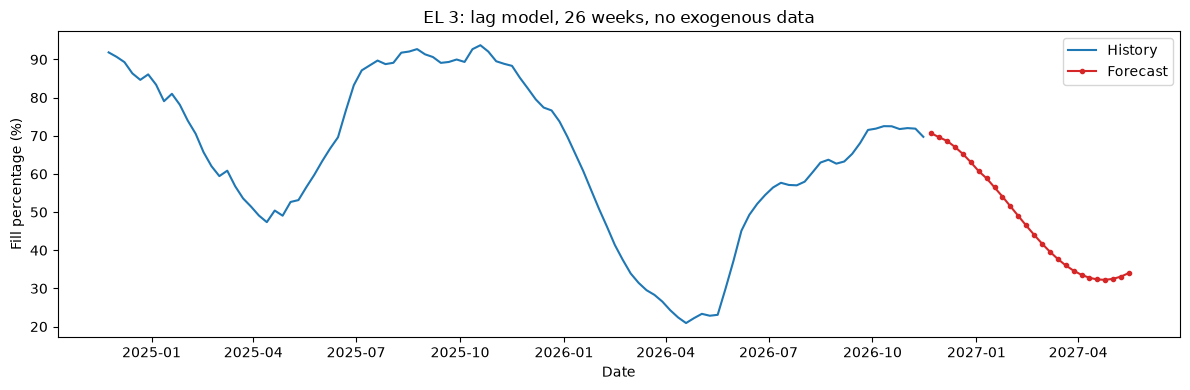

In [42]:
# Lag model, no exogenous data, 26 weeks ahead
result, sec = forecast_reservoir("EL", 3, sources=[], model="lags", n_lags=2, horizon=26)
print(f"Run time: {sec:.2f} s")
plot_forecast(result, title="EL 3: lag model, 26 weeks, no exogenous data")
plt.show()

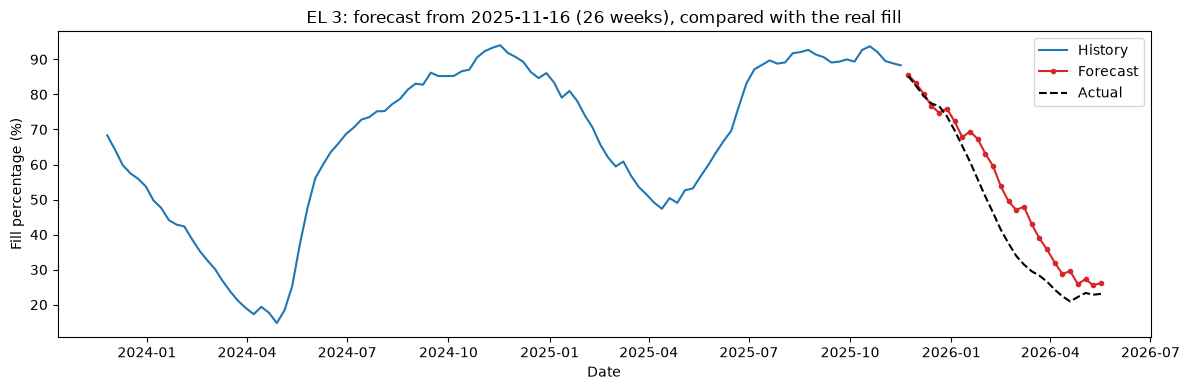

In [43]:
# Pretend we are one year back, so we can compare with what really happened
cut = fill.index[-53]
result, sec = forecast_fill(fill, exog_all, model="snarimax", end=cut, horizon=26)
plot_forecast(result, actual=fill, title=f"EL 3: forecast from {cut.date()} (26 weeks), compared with the real fill")
plt.show()

### Comments on the results 

- **Defaults (SNARIMAX + weather):** the fill in EL 3 is about 70 % now, which is lower than at the same time
  last year (about 90 %). The model forecasts that the fill goes down to about 22 % in February 2027. It falls
  about as fast as last winter, but since it starts lower, it ends lower. Run time: 0.14 s.

- **Lag model, 26 weeks:** the forecast goes smoothly down to about 32 % in April 2027 and then starts to go up
  again. So the model has learned the yearly pattern with the lowest fill in spring. The curve is smoother
  and falls more slowly than SNARIMAX. Run time: 0.06 s.

- **One year back:** the forecast from 16 November 2025 follows the real fill well for the first 5-6 weeks.
  After that the real fill fell faster than the model expected, so the forecast is up to about 10 percentage
  points too high in February and March. At the end (May 2026) they are close again (about 26 % against
  23 %). This shows that the forecast is good for the first weeks and becomes more uncertain further ahead.

### Testing different settings

**How I tested:** A forecast can look good by chance for one date, so I used a *rolling backtest*: I go back
in time to 8 different start points, 13 weeks apart (one per quarter, so all seasons are tested). From each
start point the model only sees the history before that date, forecasts 12 weeks ahead, and I compare with
the real fill. The error is the mean absolute error (MAE) in percentage points (pp), averaged over the 8 start
points.

To know if a model is actually good, I also compare with two simple baselines that need no model:
- **Persistence:** the fill stays as it is in the last week.
- **Last year:** the fill is the same as the same week last year, moved up or down so it starts at the last
  known value.

I tested 6 model settings (SNARIMAX with and without seasonal terms, and the lag model with 2 and 4 lags),
3 lengths of history (2, 3 and 5 years) and 3 choices of data sources (none, weather, weather + currency).

In [44]:
def backtest(fill, exog=None, n_origins=8, horizon=12, **kwargs):
    """Rolling backtest: forecast from n_origins start points (13 weeks apart) and compare with the truth.
    Returns the mean absolute error (percentage points) and the mean run time per forecast."""
    y = fill.dropna()
    origins = y.index[-(horizon + 1)::-13][:n_origins]
    errors, times = [], []
    for o in origins:
        result, sec = forecast_fill(y, exog, horizon=horizon, end=o, **kwargs)
        fc = result[result.kind == "forecast"]["fill"]
        errors.append((fc - y.reindex(fc.index)).abs().mean())
        times.append(sec)
    return float(np.nanmean(errors)), float(np.mean(times))

def baseline_mae(fill, n_origins=8, horizon=12):
    """MAE for the two baselines, with the same start points as the backtest."""
    y = fill.dropna()
    out = {"persistence": [], "last year": []}
    for o in y.index[-(horizon + 1)::-13][:n_origins]:
        future = y[o:].iloc[1:horizon + 1]
        out["persistence"].append((future - y[o]).abs().mean())
        last_year = y.shift(52).reindex(future.index) - y.shift(52)[o] + y[o]
        out["last year"].append((future - last_year).abs().mean())
    return {k: float(np.mean(v)) for k, v in out.items()}

baselines = baseline_mae(fill)
baselines

{'persistence': 13.328836708333334, 'last year': 5.833022968749996}

In [45]:
# The settings I test
model_settings = {
    "SNARIMAX(2,1,0)(0,1,0)52": dict(model="snarimax", p=2, d=1, q=0, sp=0, sd=1, sq=0),
    "SNARIMAX(1,0,0)(1,1,0)52": dict(model="snarimax", p=1, d=0, q=0, sp=1, sd=1, sq=0),
    "SNARIMAX(2,1,1)":          dict(model="snarimax", p=2, d=1, q=1, sp=0, sd=0, sq=0),
    "SNARIMAX(1,1,0)":          dict(model="snarimax", p=1, d=1, q=0, sp=0, sd=0, sq=0),
    "Lags (2)":                 dict(model="lags", n_lags=2),
    "Lags (4)":                 dict(model="lags", n_lags=4),
}
weather_cols = ["temperature_2m_mean", "precipitation_sum", "snowfall_sum"]
source_settings = {"none": [], "weather": ["weather"], "weather + currency": ["weather", "currency"]}
exog_for = {"none": None,                                           # the exogenous columns for each choice
            "weather": exog_all[weather_cols],
            "weather + currency": exog_all[weather_cols + ["EUR", "USD"]]}
histories = [104, 156, 260]                                         # 2, 3 and 5 years

rows = []
t_start = time.perf_counter()
for m_name, m_kw in model_settings.items():
    for s_name, ex in exog_for.items():
        for h in histories:
            mae, sec = backtest(fill, ex, history_weeks=h, **m_kw)
            rows.append({"model": m_name, "sources": s_name, "history_weeks": h,
                         "MAE (pp)": round(mae, 2), "seconds per run": round(sec, 3)})

results = pd.DataFrame(rows).sort_values("MAE (pp)")
print(f"{len(rows)} settings x 8 start points in {time.perf_counter() - t_start:.0f} s")
print("Baselines:", {k: round(v, 2) for k, v in baselines.items()})
results.head(15)

54 settings x 8 start points in 19 s
Baselines: {'persistence': 13.33, 'last year': 5.83}


,model,sources,history_weeks,MAE (pp),seconds per run
26,"SNARIMAX(2,1,1)",weather + currency,260,4.12,0.057
20,"SNARIMAX(2,1,1)",none,260,4.49,0.032
35,"SNARIMAX(1,1,0)",weather + currency,260,4.50,0.050
19,"SNARIMAX(2,1,1)",none,156,4.52,0.023
29,"SNARIMAX(1,1,0)",none,260,4.69,0.008
23,"SNARIMAX(2,1,1)",weather,260,4.72,0.115
28,"SNARIMAX(1,1,0)",none,156,4.83,0.006
32,"SNARIMAX(1,1,0)",weather,260,5.00,0.048
22,"SNARIMAX(2,1,1)",weather,156,5.06,0.115
27,"SNARIMAX(1,1,0)",none,104,5.09,0.005


In [46]:
# Mean error per model, per data source and per length of history
for col in ["model", "sources", "history_weeks"]:
    display(results.groupby(col)["MAE (pp)"].mean().round(2).sort_values().to_frame())

,MAE (pp)
model,
"SNARIMAX(2,1,1)",5.00
"SNARIMAX(1,1,0)",5.23
"SNARIMAX(2,1,0)(0,1,0)52",6.86
Lags (4),11.76
Lags (2),13.15
"SNARIMAX(1,0,0)(1,1,0)52",21.55


,MAE (pp)
sources,
weather + currency,9.09
none,11.13
weather,11.55


,MAE (pp)
history_weeks,
260,9.34
156,10.34
104,12.09


In [47]:
# Does the result hold for other areas? Test the best 3 settings on all EL areas (without new downloads:
# only the fill itself, since weather is only downloaded for EL 3)
best3 = results.head(3)
check = []
for _, row in best3.iterrows():
    for n in [1, 2, 3, 4, 5]:
        mae, _ = backtest(fill_series("EL", n), None, history_weeks=row.history_weeks, **model_settings[row.model])
        check.append({"model": row.model, "history_weeks": row.history_weeks, "area": f"EL {n}", "MAE (pp)": round(mae, 2)})
pd.DataFrame(check).pivot_table(index=["model", "history_weeks"], columns="area", values="MAE (pp)")

,area,EL 1,EL 2,EL 3,EL 4,EL 5
model,history_weeks,,,,,
"SNARIMAX(1,1,0)",260,6.91,4.91,4.69,4.86,4.55
"SNARIMAX(2,1,1)",260,6.73,4.68,4.49,4.85,4.64


{'sources': ['weather', 'currency'], 'history_weeks': 260, 'horizon': 12, 'model': 'snarimax', 'p': 2, 'd': 1, 'q': 1, 'sp': 0, 'sd': 0, 'sq': 0}


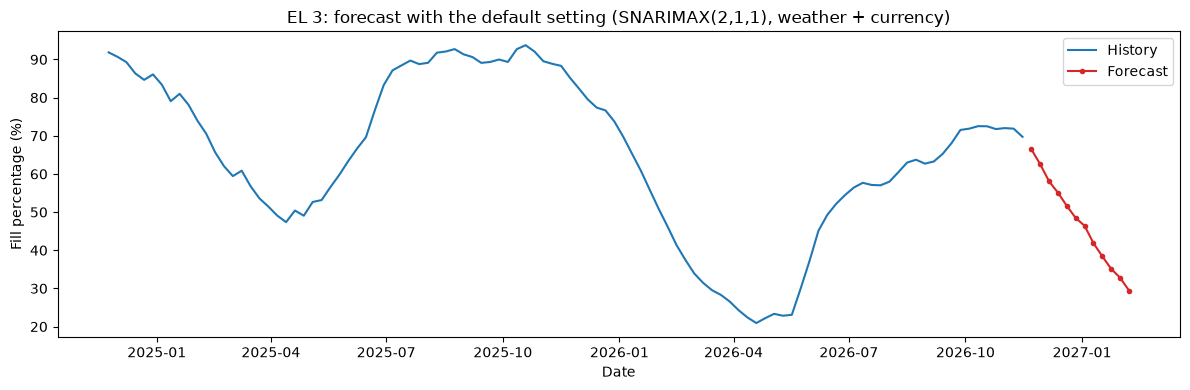

In [48]:
# The best setting is saved, so the Streamlit app can use it as the default
best = results.iloc[0]
DEFAULTS = {"sources": source_settings[best.sources], "history_weeks": int(best.history_weeks),
            "horizon": 12, **model_settings[best.model]}
with open(DATA_DIR / "forecast_defaults.json", "w") as f:
    json.dump(DEFAULTS, f, indent=2)
print(DEFAULTS)

# The forecast with the default setting
result, sec = forecast_reservoir("EL", 3, **DEFAULTS)
plot_forecast(result, title=f"EL 3: forecast with the default setting ({best.model}, {best.sources})")
plt.show()

### Findings 

- **Run time:** one forecast only takes between 0.01 and 0.16 s on weekly data, and the whole test with 54
  settings and 8 start points (432 forecasts) took 37 s. So the model itself is fast, it is the weather
  download that takes time. Since i use daily weather instead of hourly like in part 3, the download from 2018
  until today only took 3.5 s. Weekly data for the model and daily data for the weather worked well.
- **Baselines:** just keeping the fill as it is ("persistence") gave an error of 13.33 pp, and using the same
  week last year gave 5.83 pp. I was surprised that "last year" was so hard to beat, but it makes sense since
  the reservoirs follow almost the same pattern every year.
- **Best setting:** SNARIMAX(2,1,1) with weather + currency and 5 years of history was best, with an error of
  4.12 pp. That is about 30 % better than "last year" and three times better than persistence.
- **Models:** SNARIMAX(2,1,1) and SNARIMAX(1,1,0) were clearly the best (5.00 and 5.23 pp on average).
  Seasonal differencing did not help, and SNARIMAX(1,0,0)(1,1,0)52 was really unstable (21.55 pp). The lag
  models were a lot worse (11.8-13.2 pp), even worse than just using last year.
- **History:** a longer history gave better forecasts: 9.34 pp for 5 years, 10.34 pp for 3 years and 12.09 pp
  for 2 years. I think the model needs several years to learn the yearly pattern.
- **Data sources:** for the best model the difference was quite small: 4.49 pp without exogenous data, 4.72 pp
  with weather and 4.12 pp with weather + currency. I expected the weather to help more, but in the forecast
  weeks the weather is unknown, so I have to use the average of earlier years, and that is probably why.
  That currency helped is probably partly luck with only 8 start points, because the exchange rate does
  not really control how much water there is in the reservoirs.
- **Other areas:** the best settings gave about 4.5-4.9 pp for EL 2-5, but about 6.8 pp for EL 1, so EL 1 is
  harder to forecast. The table only has two rows, because the two best settings are both SNARIMAX(2,1,1)
  with 260 weeks, and the test for EL 1-5 does not use exogenous data.
- **Experiences:** at first the lag model gave really bad forecasts, because it learned the level of the fill
  (about 60 %) way too slowly when it only goes through the data once. I fixed it by also standardising the
  target with `TargetStandardScaler`, but it was still worse than SNARIMAX.

The best setting is saved in `data/forecast_defaults.json` and is used as the default in the Streamlit app.
With this setting, the forecast for EL 3 goes from about 67 % now to about 30 % in February 2027.

## Log

In part 4 the focus moved from looking at the data to forecasting it, and the app got a new structure.

In the notebook I first made a function for the exchange rates from Norges Bank. The API was easy to use
once I understood how the address is built, with the currencies joined with a plus sign. Then I looked at
time zones. I found that I had stored both the ENTSO-E data and the weather in UTC without a time zone, while
Magasinstatistikk and Norges Bank only have Norwegian dates. For weekly values the difference was small, but
for daily values you could see big differences. I decided to change everything to Norwegian
time and make weekly values that match the weeks in Magasinstatistikk.

For the forecast I used SNARIMAX from River and a lag model. Since the fill only has one value per week, I
made the model weekly and downloaded daily weather instead of hourly, which made the download 24 times
smaller. To test fairly I made forecasts from eight start points in the past and compared them with two
simple baselines. SNARIMAX(2,1,1) with five years of history was best, while the lag model was much worse.
It was interesting that "same as last year" was so hard to beat.

In Streamlit, I first made a sketch in Google Drive with all the elements, and then grouped the pages into
Explore, Anomalies and Forecast with `st.navigation`. All shared code went into `utils.py`, and all plots were
changed from matplotlib to Plotly with a common theme. The front page got a map with the areas as GeoJSON,
where a click on an area selects it for all pages through the session state. I also made a correlation page
and a forecast page with a Plotly animation.

When I played with the correlation page, I saw that snowfall has a negative correlation with the weekly
change in fill in the same week, but a positive correlation of about 0.4 about 20 weeks later. This fits with
snow that is stored in the mountains in winter and melts into the reservoirs in spring, so the winter weather
can be useful for predicting the fill in spring.

I chose three bonus tasks:
- waiting time (spinners, progress bars and caching)
- error handling (clear messages instead of crashes when an API or the database fails)
- confidence intervals with `optim.losses.Quantile` on the forecast page.

The hardest part for me was the forecasting. It took some time to understand what the SNARIMAX parameters
mean, and why the lag model gave so bad forecasts at first. Testing many settings in a fair way helped me
understand which choices actually matter.